# 3. Segmentation

Two ways to find segments:
1. latent class regression (LC) on the ratings, estimated with EM. Each respondent belongs to one segment, and all 20 of their ratings come from that segment's partworths. Membership is estimated per respondent
2. clustering (k-means, Gaussian mixture) of the HB partworths.

Then I check how many segments the data support and how stable the segments are.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

from data import load_data, encode
from models import hb, add_const, rmse, hit_rate, holdout_splits
from segments import latent_class, lc_assign, lc_predict

design, online, offline = load_data()
X = encode(design)
cols = list(X.columns)
import warnings
warnings.filterwarnings("ignore")

## Latent class: raw ratings vs centered ratings

Some respondents rate everything high and others rate everything low. If LC is run on raw ratings, it can create segments of "generous" and "strict" raters instead of segments with different tastes. To avoid this I subtract each respondent's mean rating before estimating LC (the "centered" model). Then the segments differ only in partworths.

In [2]:
Ks = range(1, 9)
fits_raw = {K: latent_class(online, X, K, centered=False) for K in Ks}
fits = {K: latent_class(online, X, K, centered=True) for K in Ks}

lc_table = pd.DataFrame({
    "BIC raw": [fits_raw[K]["bic"] for K in Ks],
    "BIC centered": [fits[K]["bic"] for K in Ks],
    "ICL centered": [fits[K]["icl"] for K in Ks],
    "smallest segment": [fits[K]["pi"].min() for K in Ks],
}, index=pd.Index(Ks, name="K")).round(2)
lc_table

,BIC raw,BIC centered,ICL centered,smallest segment
K,,,,
1,7418.37,6651.62,6651.62,1.00
2,7185.97,6379.44,6399.35,0.48
3,6987.84,6335.15,6368.65,0.24
4,6920.74,6297.07,6336.84,0.18
5,6904.25,6264.91,6310.83,0.11
6,6899.90,6252.14,6293.67,0.11
7,6900.17,6252.49,6298.65,0.02
8,6898.82,6246.71,6289.61,0.02


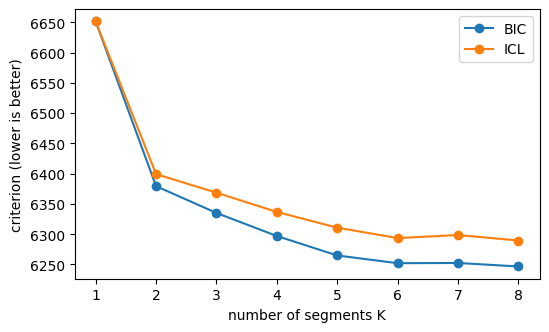

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(Ks, lc_table["BIC centered"], marker="o", label="BIC")
ax.plot(Ks, lc_table["ICL centered"], marker="o", label="ICL")
ax.set_xlabel("number of segments K")
ax.set_ylabel("criterion (lower is better)")
ax.legend()
plt.show()

Centering matters: on raw ratings part of what LC finds is differences in rating levels. With centered ratings, BIC keeps falling up to K = 8 and is nearly flat between 6 and 8, and from K = 7 on the smallest segment has only about 2% of respondents. ICL, which also penalizes unclear segment membership, gives a similar picture. So by fit criteria the data would support many small segments.

## Latent class: out-of-sample prediction

Hide 4 bags per respondent, estimate on 16, predict the hidden ratings. HB is the benchmark.

In [4]:
splits = holdout_splits(X)
rows = []
for s, (train, test) in enumerate(splits):
    Rtr, Rte = online[:, train], online[:, test]
    for K in Ks:
        f = latent_class(Rtr, X.iloc[train], K, n_starts=10, seed=s)
        pred = lc_predict(Rtr, X.iloc[train], X.iloc[test], f)
        rows.append({"model": f"LC K={K}", "K": K, "rmse": rmse(pred, Rte), "hit rate": hit_rate(pred, Rte)})
    pred = hb(Rtr, X.iloc[train], n_iter=4000, burn=1000, seed=s)["B"].mean(0) @ add_const(X.iloc[test]).T
    rows.append({"model": "HB", "K": np.nan, "rmse": rmse(pred, Rte), "hit rate": hit_rate(pred, Rte)})
cv = pd.DataFrame(rows)
cv_table = cv.groupby("model", sort=False)[["rmse", "hit rate"]].agg(["mean", "sem"]).round(3)
cv_table

rmse        hit rate       
         mean    sem     mean    sem
model                               
LC K=1  1.059  0.032    0.731  0.040
LC K=2  0.993  0.025    0.729  0.040
LC K=3  0.984  0.022    0.741  0.033
LC K=4  0.978  0.023    0.745  0.033
LC K=5  0.983  0.026    0.747  0.033
LC K=6  0.983  0.030    0.752  0.032
LC K=7  0.973  0.025    0.743  0.025
LC K=8  0.973  0.028    0.761  0.024
HB      0.880  0.021    0.791  0.021

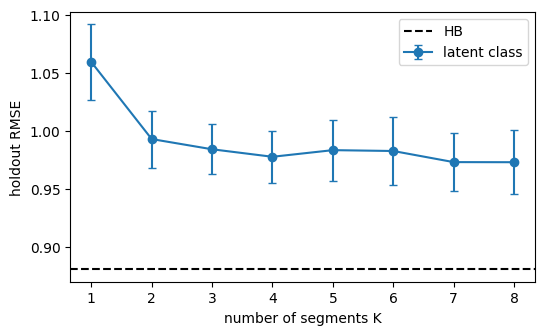

In [5]:
lc_cv = cv[cv["model"] != "HB"].groupby("K")["rmse"].agg(["mean", "sem"])
hb_rmse = cv.loc[cv["model"] == "HB", "rmse"].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(lc_cv.index, lc_cv["mean"], yerr=lc_cv["sem"], marker="o", capsize=3, label="latent class")
ax.axhline(hb_rmse, color="k", ls="--", label="HB")
ax.set_xlabel("number of segments K")
ax.set_ylabel("holdout RMSE")
ax.legend()
plt.show()

Prediction improves a lot from 1 to 3 segments and then flattens. Even with 8 segments LC is clearly worse than HB. This suggests that preferences vary continuously across people: segments capture a part of this variation, but a lot of it is within segments.

## Clustering HB partworths

k-means and a Gaussian mixture (diagonal covariance) on standardized HB partworths, without the intercept.

In [6]:
B_hb = hb(online, X, seed=0)["B"].mean(0)[:, 1:]
S = StandardScaler().fit_transform(B_hb)

rows = []
for K in range(1, 7):
    gmm = GaussianMixture(K, covariance_type="diag", n_init=10, random_state=0).fit(S)
    row = {"K": K, "GMM BIC": gmm.bic(S)}
    if K > 1:
        km = KMeans(K, n_init=20, random_state=0).fit(S)
        row["k-means silhouette"] = silhouette_score(S, km.labels_)
    rows.append(row)
pd.DataFrame(rows).set_index("K").round(3)

,GMM BIC,k-means silhouette
K,,
1,3202.461,NaN
2,3064.551,0.209
3,3070.532,0.165
4,3076.106,0.170
5,3102.534,0.179
6,3133.708,0.164


Silhouette scores are low (around 0.2), so there are no well separated clusters in the partworths. The Gaussian mixture prefers 2-3 clusters.

## Stability

Bootstrap: resample respondents, re-estimate the segments, assign all original respondents with the new model and compare with the original assignment (adjusted Rand index, 1 = same partition, 0 = random). I also compare LC and k-means segments with each other.

In [7]:
rng = np.random.default_rng(0)
rows = []
for K in [2, 3, 4, 5]:
    km_full = KMeans(K, n_init=20, random_state=0).fit(S)
    ari_lc, ari_km = [], []
    for b in range(50):
        idx = rng.integers(0, len(online), len(online))
        f = latent_class(online[idx], X, K, n_starts=10, seed=b)
        ari_lc.append(adjusted_rand_score(fits[K]["labels"], lc_assign(online, X, f).argmax(1)))
        km = KMeans(K, n_init=10, random_state=b).fit(S[idx])
        ari_km.append(adjusted_rand_score(km_full.labels_, km.predict(S)))
    rows.append({
        "K": K,
        "LC stability": np.mean(ari_lc),
        "k-means stability": np.mean(ari_km),
        "LC vs k-means": adjusted_rand_score(fits[K]["labels"], km_full.labels_),
    })
pd.DataFrame(rows).set_index("K").round(2)

,LC stability,k-means stability,LC vs k-means
K,,,
2,0.84,0.77,0.30
3,0.54,0.60,0.25
4,0.43,0.56,0.13
5,0.45,0.57,0.18


Two segments are stable under resampling. From three segments on, the assignment changes a lot from one bootstrap sample to another. LC and k-means also find quite different segments, so the exact segment boundaries depend on the method.

## What the segments look like

Partworths of the LC segments for K = 2 and K = 3, and willingness to pay (WTP) for each feature: how many dollars a segment would pay for it, computed as 60 * partworth / (-price coefficient).

In [8]:
def segment_table(fit):
    t = pd.DataFrame(fit["B"].T, index=cols, columns=[f"segment {k + 1}" for k in range(len(fit["pi"]))])
    t.loc["share"] = fit["pi"]
    return t.round(2)

def wtp_table(fit):
    B = fit["B"]
    wtp = 60 * B[:, 1:] / (-B[:, [0]])
    return pd.DataFrame(wtp.T, index=cols[1:], columns=[f"segment {k + 1}" for k in range(len(fit["pi"]))]).round(0)

segment_table(fits[2])

,segment 1,segment 2
price,-0.01,-0.01
exterior_reflective,-0.25,-0.38
exterior_colorful,-0.25,-1.95
exterior_blue,-0.21,-0.23
size_large,0.28,0.25
strap_pad_yes,0.70,0.31
pocket_yes,0.66,0.22
interior_file_divider,0.48,0.32
interior_laptop,0.76,0.46
share,0.52,0.48


In [9]:
segment_table(fits[3])

,segment 1,segment 2,segment 3
price,-0.02,-0.01,-0.01
exterior_reflective,-0.12,-0.37,-0.38
exterior_colorful,-0.69,0.04,-1.94
exterior_blue,-0.16,-0.29,-0.21
size_large,0.77,-0.08,0.23
strap_pad_yes,0.90,0.55,0.29
pocket_yes,0.68,0.65,0.20
interior_file_divider,0.37,0.56,0.33
interior_laptop,0.61,0.89,0.46
share,0.24,0.29,0.47


In [10]:
wtp_table(fits[3])

,segment 1,segment 2,segment 3
exterior_reflective,-431.0,-1795.0,-2907.0
exterior_colorful,-2504.0,185.0,-14930.0
exterior_blue,-570.0,-1431.0,-1588.0
size_large,2820.0,-379.0,1778.0
strap_pad_yes,3292.0,2681.0,2232.0
pocket_yes,2496.0,3190.0,1564.0
interior_file_divider,1340.0,2742.0,2548.0
interior_laptop,2209.0,4334.0,3536.0


With two segments, the split is mostly about price and exterior: segment 1 is more price sensitive and values all functional features more, segment 2 is less price sensitive but strongly dislikes the colorful exterior. With three segments: segment 1 (24%) is the most price sensitive and wants a large bag with a strap pad, segment 2 (29%) does not mind the colorful exterior and values the laptop compartment most, segment 3 (47%) is the least price sensitive and strongly dislikes the colorful exterior. WTP numbers above about $100 should not be read literally: they extrapolate far outside the $120-$180 price range.

## Summary

The criteria do not agree on the number of segments: BIC points to 6-8, out-of-sample prediction stops improving after 3, and only 2 segments are stable. Statistically, heterogeneity in this data looks continuous rather than made of a few clear groups. This does not tell us yet whether segmentation is useful for the firm. The next part checks how much revenue segments bring and which K is best for revenue.